CISC7204 Assignment 02 — MC63582 FAN ZIQIAN

# Waffle Charts, Word Clouds, and Regression Plots

## Prepare the data

In [9]:
import numpy as np
import pandas as pd
%matplotlib inline
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.style.use('ggplot')

df_can = pd.read_excel(
    'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/Data%20Files/Canada.xlsx',
    sheet_name='Canada by Citizenship',
    skiprows=range(20),
    skipfooter=2,
)
df_can.drop(['AREA', 'REG', 'DEV', 'Type', 'Coverage'], axis=1, inplace=True)
df_can.rename(columns={'OdName': 'Country', 'AreaName': 'Continent', 'RegName': 'Region'}, inplace=True)
df_can['Total'] = df_can.select_dtypes(include='number').sum(axis=1)
df_can.set_index('Country', inplace=True)
df_can.columns = list(map(str, df_can.columns))
years = list(map(str, range(1980, 2014)))
print('data dimensions:', df_can.shape)
df_can.head(3)

import seaborn as sns
from wordcloud import WordCloud
from pywaffle import Waffle


data dimensions: (195, 38)


## Waffle chart

Denmark, Norway, and Sweden. Tile counts follow each country's share of the three-country total.

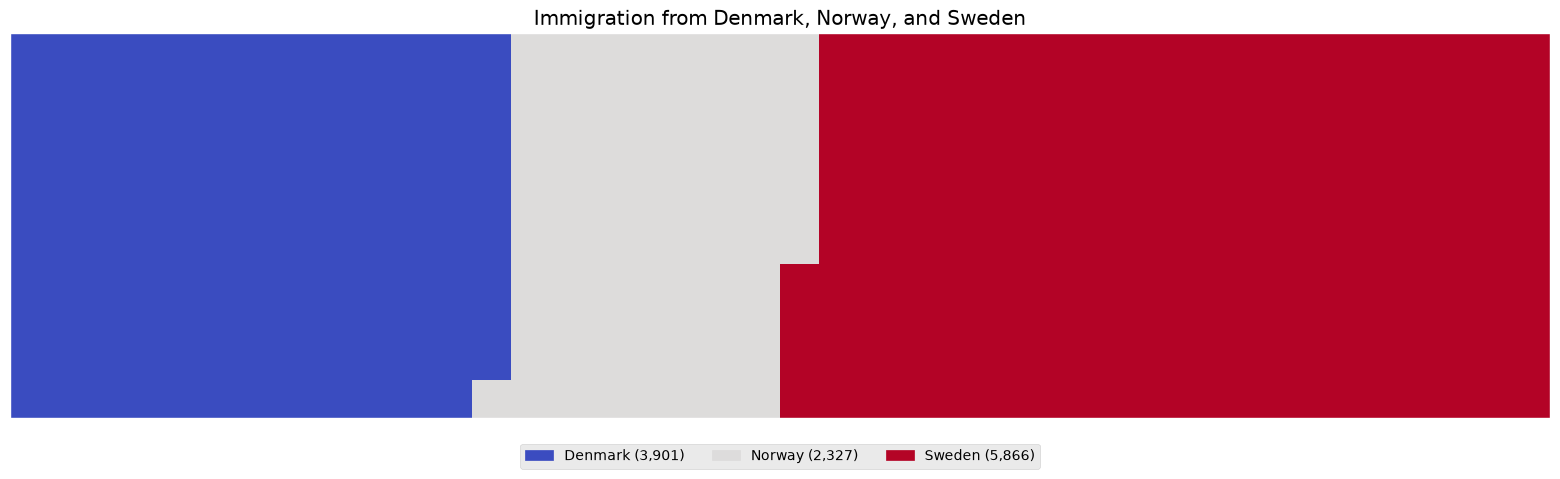

Tiles per category: {'Denmark': 129, 'Norway': 77, 'Sweden': 194}


In [10]:
df_dsn = df_can.loc[['Denmark', 'Norway', 'Sweden'], :]
categories = df_dsn.index.values
values = df_dsn['Total']

def create_waffle_chart(categories, values, height, width, colormap):
    total_values = sum(values)
    category_proportions = [float(value) / total_values for value in values]
    total_num_tiles = width * height
    tiles_per_category = [round(proportion * total_num_tiles) for proportion in category_proportions]
    # Keep the tile count equal to the grid size after rounding.
    tiles_per_category[-1] = total_num_tiles - sum(tiles_per_category[:-1])
    waffle = np.zeros((height, width))
    category_index = 0
    tile_index = 0
    for col in range(width):
        for row in range(height):
            tile_index += 1
            if tile_index > sum(tiles_per_category[: category_index + 1]):
                category_index += 1
            waffle[row, col] = category_index
    fig = plt.figure(figsize=(width / 2, height / 2))
    ax = fig.add_subplot(1, 1, 1)
    ax.matshow(waffle, cmap=plt.colormaps[colormap])
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title('Immigration from Denmark, Norway, and Sweden')
    # Legend uses one tile color per category.
    color_map = plt.colormaps[colormap]
    labels = [f'{cat} ({val:,.0f})' for cat, val in zip(categories, values)]
    handles = [
        plt.Rectangle((0, 0), 1, 1, color=color_map(i / max(len(categories) - 1, 1)))
        for i in range(len(categories))
    ]
    ax.legend(handles, labels, loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.15))
    plt.show()
    return tiles_per_category

tiles = create_waffle_chart(categories, values, height=10, width=40, colormap='coolwarm')
print('Tiles per category:', dict(zip(categories, tiles)))


The same comparison with `pywaffle`, which draws the legend for us.

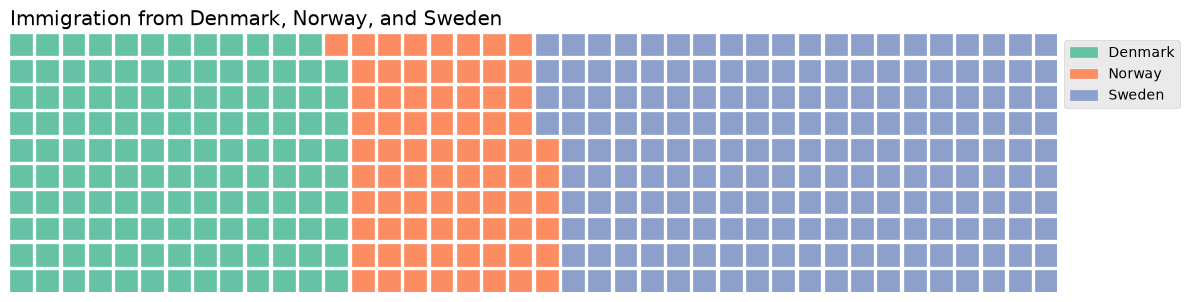

In [11]:
fig = plt.figure(
    FigureClass=Waffle,
    rows=10,
    columns=40,
    values=dict(zip(categories, values)),
    legend={'loc': 'upper left', 'bbox_to_anchor': (1, 1)},
    figsize=(12, 4),
    title={'label': 'Immigration from Denmark, Norway, and Sweden', 'loc': 'left'},
)
plt.show()


**Question.** Waffle chart of the three countries with the largest total immigration.

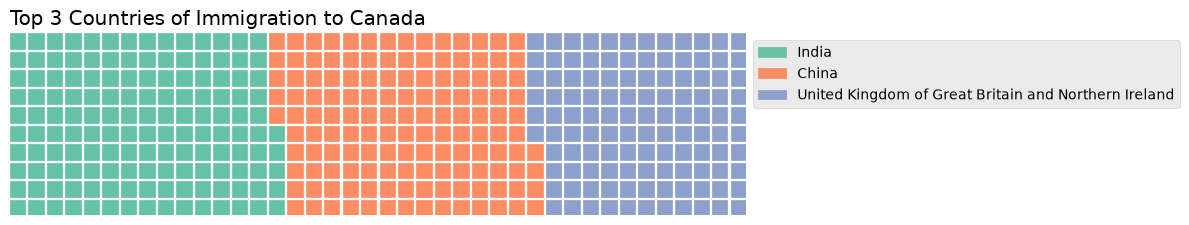

In [12]:
top3 = df_can.sort_values(by='Total', ascending=False).head(3)
fig = plt.figure(
    FigureClass=Waffle,
    rows=10,
    columns=40,
    values=top3['Total'].to_dict(),
    legend={'loc': 'upper left', 'bbox_to_anchor': (1, 1)},
    figsize=(12, 4),
    title={'label': 'Top 3 Countries of Immigration to Canada', 'loc': 'left'},
)
plt.show()


## Word cloud

*Alice's Adventures in Wonderland*, then a cloud whose word size is a country's total immigration.

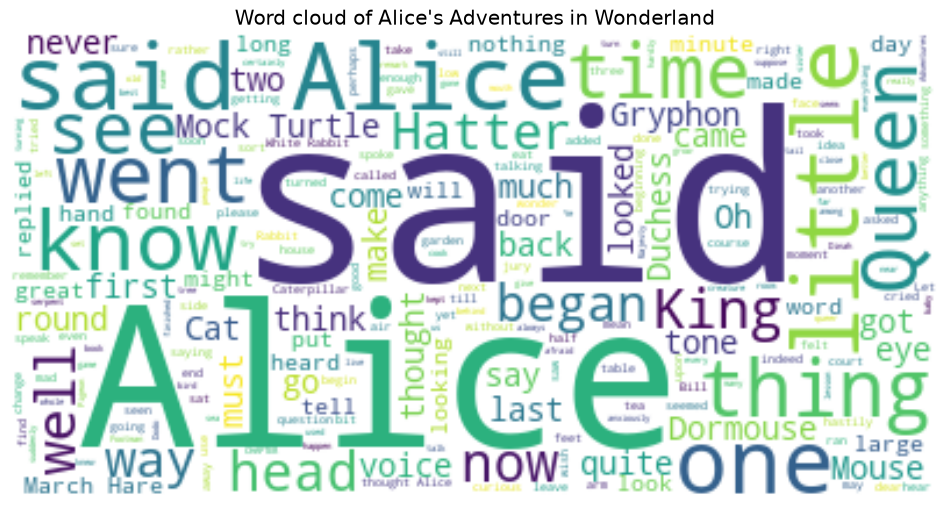

In [13]:
import urllib.request
alice_path = '/tmp/alice_novel.txt'
urllib.request.urlretrieve('https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/Data%20Files/alice_novel.txt', alice_path)
alice_novel = open(alice_path, 'r', encoding='utf-8', errors='ignore').read()
alice_wc = WordCloud(background_color='white', max_words=2000).generate(alice_novel)
plt.figure(figsize=(12, 8))
plt.imshow(alice_wc, interpolation='bilinear')
plt.axis('off')
plt.title("Word cloud of Alice's Adventures in Wonderland")
plt.show()


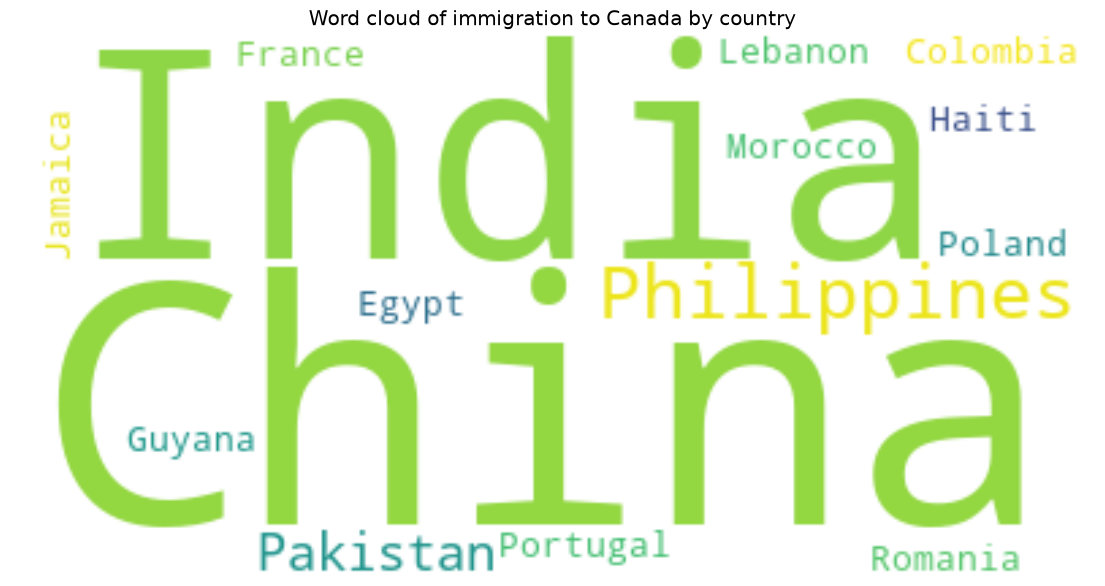

In [14]:
total_immigration = df_can['Total'].sum()
max_words = 90
word_string = ''
for country in df_can.index.values:
    if len(str(country).split(' ')) == 1:
        repeat_num_times = int(df_can.loc[country, 'Total'] / float(total_immigration) * max_words)
        word_string = word_string + ((country + ' ') * repeat_num_times)
wordcloud = WordCloud(background_color='white').generate(word_string)
plt.figure(figsize=(14, 8))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word cloud of immigration to Canada by country')
plt.show()


## Regression plot

Total immigration to Canada against year, then the same plot for Denmark, Norway, and Sweden combined.

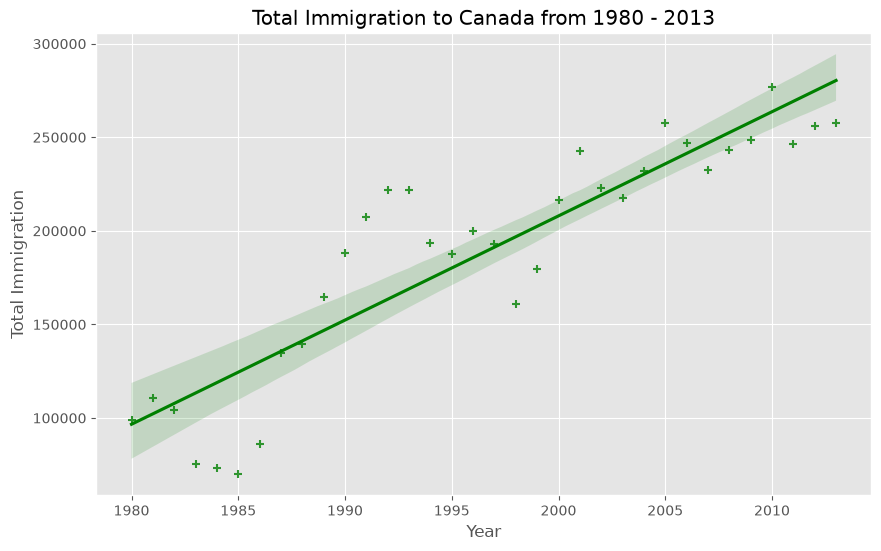

In [15]:
df_tot = pd.DataFrame(df_can[years].sum(axis=0))
df_tot.index = df_tot.index.map(int)
df_tot.reset_index(inplace=True)
df_tot.columns = ['year', 'total']
plt.figure(figsize=(10, 6))
sns.regplot(x='year', y='total', data=df_tot, color='green', marker='+')
plt.title('Total Immigration to Canada from 1980 - 2013')
plt.xlabel('Year')
plt.ylabel('Total Immigration')
plt.show()


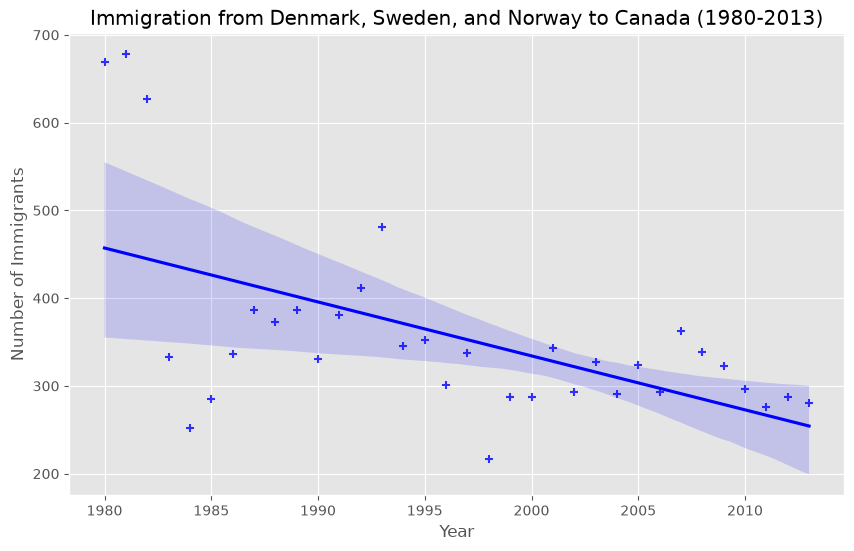

In [16]:
df_countries = df_can.loc[['Denmark', 'Norway', 'Sweden'], years].sum(axis=0)
df_reg = pd.DataFrame(df_countries)
df_reg.index = df_reg.index.map(int)
df_reg.reset_index(inplace=True)
df_reg.columns = ['year', 'total']
plt.figure(figsize=(10, 6))
ax = sns.regplot(x='year', y='total', data=df_reg, color='blue', marker='+')
ax.set_title('Immigration from Denmark, Sweden, and Norway to Canada (1980-2013)')
ax.set_xlabel('Year')
ax.set_ylabel('Number of Immigrants')
plt.show()
